In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Return to the project root if the notebook is opened from the notebooks folder
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

# File paths
prof_data = "data/001MoDe_R1.csv"
personal_data = "data/data.csv"

# Load a dataset and calculate its sampling frequency
def load_dataset(file_path):

    with open(file_path, "r") as file:
        first_line = file.readline().strip()

    data = np.loadtxt(file_path, delimiter=",", skiprows=4)

    # Keep only valid samples
    data = data[data[:, 0] > 0]

    timestamps = data[:, 0]

    # Calculate sampling frequency
    time_differences = np.diff(timestamps)
    time_differences = time_differences[time_differences > 0]

    sampling_frequency = 1000 / np.median(time_differences)

    # Calculate recording duration
    duration = (timestamps[-1] - timestamps[0]) / 1000

    return {
        "data": data,
        "samples": len(data),
        "frequency": sampling_frequency,
        "duration": duration
    }

# Load both datasets
prof = load_dataset(prof_data)
personal = load_dataset(personal_data)

print("Professor dataset")
print("Number of samples:", prof["samples"])
print("Sampling frequency:", round(prof["frequency"], 2), "Hz")
print("Duration:", round(prof["duration"], 2), "seconds")

print("\nPersonal dataset")
print("Number of samples:", personal["samples"])
print("Sampling frequency:", round(personal["frequency"], 2), "Hz")
print("Duration:", round(personal["duration"], 2), "seconds")

Professor dataset
Number of samples: 19588
Sampling frequency: 200.0 Hz
Duration: 180.1 seconds

Personal dataset
Number of samples: 2202
Sampling frequency: 76.92 Hz
Duration: 108.26 seconds


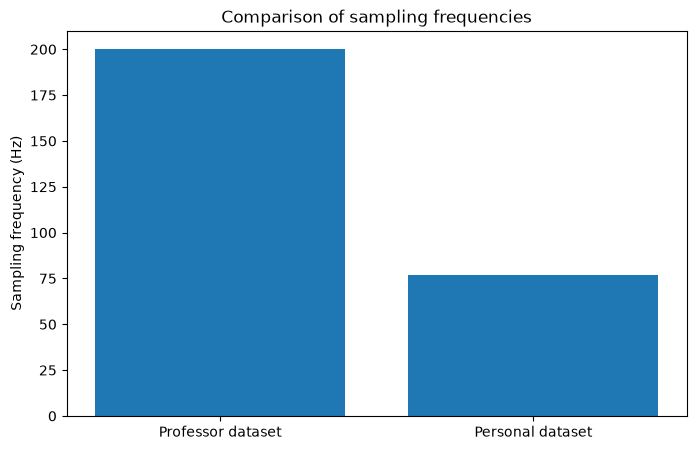

In [2]:
# Compare sampling frequencies

datasets = ["Professor dataset", "Personal dataset"]
frequencies = [prof["frequency"], personal["frequency"]]

plt.figure(figsize=(8, 5))

plt.bar(datasets, frequencies)

plt.ylabel("Sampling frequency (Hz)")
plt.title("Comparison of sampling frequencies")

plt.show()

In [3]:
# Paths to marker files
prof_marker = "data/001MoDe_R1.marker.csv"
personal_marker = "data/marker.csv"

# Display the first lines of each marker file
def inspect_marker_file(file_path):

    print("\nFile:", file_path)

    with open(file_path, "r") as file:
        for i in range(10):
            line = file.readline()
            if not line:
                break
            print(line.strip())

inspect_marker_file(prof_marker)
inspect_marker_file(personal_marker)


File: data/001MoDe_R1.marker.csv
screenWidth 1104;screenHeight 661;cornerX 302;cornerY 80;centerX 552;centerY 330;externalRadius 250;internalRadius 170;borderRadius 1;cursorRadius 16;indexOfDifficulty 28.00696429476858;taskRadius 209.5;taskTolerance 47;borderColor java.awt.Color[r=255,g=255,b=255];backgroundColor java.awt.Color[r=0,g=0,b=0];cursorColorRecord java.awt.Color[r=255,g=0,b=0];cursorColorWait java.awt.Color[r=255,g=255,b=0];autoStart 3600;cycleMaxNumber 6;cycleDuration 20;software LSL-mouse;version 1.2.0rc5;task CircularTarget;isWithLSL false
2021-03-26 17:38:25.650

2021-03-26 17:38:32.325,1616776712325,KeyTyped=32 DoCycleChange
2021-03-26 17:38:32.331,1616776712331,DoCycleChange:DoStartCycleTimedSequence
2021-03-26 17:38:32.333,1616776712333,DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
2021-03-26 17:38:52.336,1616776732336,DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
2021-03-26 17:39:12.340,1616776752340,DoCycleChange:DoRecord RecordDone=1 PauseDone=1 T